Connected to merge-rna-patched-1 (Python 3.12.9)

In [ ]:
import os
import pathlib
import sys
import json
import time
import pickle
import argparse
import multiprocessing
from concurrent.futures import ProcessPoolExecutor, as_completed

_repo_root = pathlib.Path(__file__).resolve().parents[2]
os.environ.setdefault('RNA_STRUCT_HOME', str(_repo_root))
sys.path.insert(0, os.environ['RNA_STRUCT_HOME'])
os.chdir(str(_repo_root))

import numpy as np
import pandas as pd
import ast
import matplotlib
import matplotlib.pyplot as plt

from merge_rna import Experiment, MultiSystemsFit

import RNA
import bussilab.rna2d as bussi
from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy.sparse import csr_matrix

In [ ]:
# =============================================================================
# Load a single NewseqWT experiment (by concentration + replicate)
# =============================================================================
CONC_MM = 80
REP_NUMBER = 1

_PHASE1_OUTPUT_DIR = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits', 'designed_sequence',
                                   'outputs', 'experimental_turner', 'phase1', 'newseqWT')
#phase1_params = os.path.join(_PHASE1_OUTPUT_DIR, 'params1D.txt')
phase1_params = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits_paper', 'designed_sequence',
                                   'experimental', 'strand_disp_turner.txt')
_eps_b_path = os.path.join(_PHASE1_OUTPUT_DIR, 'detailed', 'NewseqWT_eps_b.npy')
_manifest_path = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence',
                               'newseq_wt_experiments_manifest.csv')


def load_single_newseq_experiment(conc_mM, rep_number, manifest_path=_manifest_path):
    """Look up one NewseqWT experiment (by concentration + replicate) in the manifest and load it."""
    manifest = pd.read_csv(manifest_path)
    match = manifest[(manifest['conc_mM'] == conc_mM) & (manifest['rep_number'] == rep_number)]
    if len(match) != 1:
        raise ValueError(f"Expected exactly one manifest row for conc_mM={conc_mM}, "
                          f"rep_number={rep_number}, found {len(match)}")
    path_txt = os.path.expandvars(match.iloc[0]['path_txt'])
    return Experiment(path_txt)


exp = load_single_newseq_experiment(CONC_MM, REP_NUMBER)
print(f"Loaded {exp.system_name} @ {exp.conc_mM}mM, {exp.temp_C}°C, rep {exp.rep_number}")

seq = exp.seq

# Build a fit struct around this one experiment purely for calculations (never calls .fit()).
fit_struct = MultiSystemsFit([exp], validation_exps=None, infer_1D_sc=False, skip_output_setup=True)

# eps_b is a System-level quantity normally derived from 0mM controls; a single non-0mM
# experiment alone would default it to zeros, so load the one already fitted/saved
# from the full 12-experiment des_seq_fits.py run instead of recomputing it.
_eps_b = np.load(_eps_b_path)
fit_struct.systems[0].eps_b = _eps_b
fit_struct.systems[0].exp_fits_train[0].eps_b = _eps_b

Loaded NewseqWT @ 80mM, 37°C, rep 1


In [ ]:
# =============================================================================
# Compute mutation probability params
# =============================================================================

def compute_mutation_probabilities(fit_struct, phase1_params):
    """Compute mutation probabilities parameters needed in the form M_i = a_i + b_i*s_i."""

    params_1D_ref = np.loadtxt(phase1_params)[:8]
    params_dict_ref = fit_struct.pack_params(params_1D_ref, fit_struct.systems[0])

    mu_r, p_b, m0, m1 = (params_dict_ref['mu_r'], params_dict_ref['p_b'],
                            params_dict_ref['m0'], params_dict_ref['m1'])

    p_bind_dict = params_dict_ref['p_bind']

    exp_fit = fit_struct.systems[0].exp_fits_train[0]

    mu_j = mu_r + exp_fit.kBT * np.log((exp_fit.conc_mM + .1) / 1000) if exp_fit.conc_mM is not None else mu_r
    penalty = exp_fit.compute_penalty_m(mu_j, p_b)

    # compute mu dependent quantities (and p(c_b|s_b,n_b))
    _, _, p_cb_given_sb_nb = exp_fit.compute_mu_dependent_quantities(mu_j, p_b, p_bind_dict) # should work with the p_bind dict that should have the same form of pack_params
    p_reaction_given_unpaired_nb = np.zeros(exp_fit.N_seq)
    p_reaction_given_paired_nb = np.zeros(exp_fit.N_seq)
    for i,nb in enumerate(exp_fit.seq):    # weighted sum over s_b=0,1
        p_reaction_given_unpaired_nb[i] = p_cb_given_sb_nb[(0, nb)] # must be multiplied by *(1-pairing_probs[i])
        p_reaction_given_paired_nb[i] = p_cb_given_sb_nb[(1, nb)] # must be multiplied by *pairing_probs[i] 

    p_cb_unpaired = exp_fit.compute_p_cb(mu_j, p_b, p_bind_dict, np.zeros(exp_fit.N_seq))
    p_cb_paired = exp_fit.compute_p_cb(mu_j, p_b, p_bind_dict, np.ones(exp_fit.N_seq))
    a_i = exp_fit.compute_mutation_profile(m0, m1, exp_fit.eps_b, p_cb_unpaired)
    b_i = exp_fit.compute_mutation_profile(m0, m1, exp_fit.eps_b, p_cb_paired) - a_i

    return p_reaction_given_unpaired_nb, p_reaction_given_paired_nb, a_i, b_i, penalty

p_reaction_given_unpaired_nb, p_reaction_given_paired_nb, a_i, b_i, penalty = compute_mutation_probabilities(fit_struct, phase1_params)

In [ ]:
def structures_sampling(seq, penalty, delta, lambda_sc=None, temperature_C=37):
    """Compute the forward model for the mutation probabilities."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    coverage_of_part_func = mol.suboptimal_coverage(delta)
    structures = mol.suboptimal_structures(delta)

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.suboptimal_to_numpy(suboptimal = structures, temperature=temperature_C+273.15) 
    return coverage_of_part_func, states, logweights

def structures_sampling_random(seq, penalty, number_samples, lambda_sc=None, temperature_C=37):
    """Compute the forward model for the mutation probabilities."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    structures = mol.sample(number_samples)
    energies = np.array([mol.evaluate(struct) for struct in structures])
    log_coverage = logsumexp(-(energies-mol.total_free_energy())*(1/(bussi._KB*(temperature_C+273.15))))

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.sample_to_numpy(samples = structures, temperature=temperature_C+273.15) 
    return np.exp(log_coverage), states, logweights

def forward_model_fixed_params(states, a_i, b_i, mask = None):
    """Compute the matrix that needs to be used for all logweights and reads,
    this stores the information about the sampled structures once.
    Returns a matrix of shape (N_samples, N_seq) with the mutation probabilities for each sampled structure and each sequence position.
    """
    if mask is None:
        mask = np.ones(len(a_i), bool)

    # unpaired (-1) -> a_i, paired -> a_i + b_i; masked columns set to 0
    mutation_probs = np.where(states == -1, a_i, a_i + b_i) * mask
    return mutation_probs

def precompute_read_factors(reads, mutation_probs, mask = None):
    """Weight-independent factors such that logM[r,s] = log P(read r | structure s) = (X @ D.T + base)[r,s].
    Masked positions (mask False) are unobserved: they contribute a factor 1 to every read
    (mutations falling on masked sites are ignored).
    Returns X (sparse, N_reads x N_observed), D (N_samples x N_observed), base (N_samples,)."""
    if mask is None:
        mask = np.ones(mutation_probs.shape[1], bool)
    observed = np.where(mask)[0]
    col_of_site = -np.ones(len(mask), int)
    col_of_site[observed] = np.arange(len(observed))

    # sparse binary matrix of mutated observed sites, shape (N_reads, N_observed)
    rows, cols = [], []
    for r, read in enumerate(reads):
        for site in read:
            if mask[site]:
                rows.append(r)
                cols.append(col_of_site[site])
    X = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(reads), len(observed)))

    # log M = sum_mut log p + sum_unmut log(1-p) = X @ (log p - log(1-p)) + sum_all log(1-p)
    P = mutation_probs[:, observed]
    log1mP = np.log1p(-P)
    D = np.log(P) - log1mP
    return X, D, log1mP.sum(axis=1)

def precompute_log_read_likelihood(reads, mutation_probs, mask = None):
    """Compute logM[r,s] = log P(read r | structure s), which does not depend on the weights.
    Returns a matrix of shape (N_reads, N_samples): memory N_reads*N_samples*8 bytes,
    use forward_model_chunked when this is too large."""
    X, D, base = precompute_read_factors(reads, mutation_probs, mask)
    return np.asarray(X @ D.T) + base[None, :]

def _loss_and_ratio_sum(N_reads, log_p, logM):
    """For a block of reads: loss = -sum_r N_r log L_r and ratio_sum_j = sum_r N_r M_rj / L_r,
    with L_r = sum_s p_s M_rs and log_p the normalized log probabilities of the structures."""
    # log read likelihoods log L_r = log sum_s P(s) M_rs
    log_L = logsumexp(logM + log_p[None, :], axis=1)
    return -np.dot(N_reads, log_L), N_reads @ np.exp(logM - log_L[:, None])

def forward_model(N_reads, logweights, logweights_0, logM):
    """Compute loss and derivatives approximately using ensemble of suboptimal structures.
    P(s) = P0(s) W(s) / Z with logweights = log(W); the gradient is taken w.r.t. W.
    logM comes from precompute_log_read_likelihood."""
    log_Z = logsumexp(logweights + logweights_0)

    # i'm considering a negative log likelihood
    loss, ratio_sum = _loss_and_ratio_sum(N_reads, logweights + logweights_0 - log_Z, logM)

    # dlogL_r/dW_j = (P0_j/Z) (M_rj/L_r - 1)
    # (multiply by W = exp(logweights - logweights_0) to get the gradient w.r.t. log W)
    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))

    return loss, grad

def forward_model_chunked(N_reads, logweights, logweights_0, X, D, base, chunk_size = 256):
    """Same as forward_model, for a number of structures too large to store logM:
    logM is rebuilt for chunk_size reads at a time, so memory is O(chunk_size*N_samples).
    X, D, base come from precompute_read_factors."""
    log_Z = logsumexp(logweights)
    log_p = logweights - log_Z

    loss = 0.
    ratio_sum = np.zeros(len(logweights), float)
    for start in range(0, X.shape[0], chunk_size):
        stop = min(start + chunk_size, X.shape[0])
        logM_chunk = np.asarray(X[start:stop] @ D.T) + base[None, :]
        chunk_loss, chunk_ratio_sum = _loss_and_ratio_sum(N_reads[start:stop], log_p, logM_chunk)
        loss += chunk_loss
        ratio_sum += chunk_ratio_sum

    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))

    return loss, grad

In [ ]:
mol_test = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)))
_,min_free_en = mol_test.mfe()
tot_free_en = mol_test.total_free_energy()

print(f"The minimum free energy is {min_free_en} and the total one {tot_free_en} in kcal/mol")

The minimum free energy is -55.652029822375894 and the total one -56.94195556640625 in kcal/mol


In [ ]:
DO_RANDOM = False
# delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
delta_kcalpermol = 5
coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

RuntimeError: Suboptimal coverage is unexpectedly larger than one: 15.463994308275282

In [ ]:
# id_str = "single_struct"
#id_str = f"r{REP_NUMBER}_true"
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

: 

In [ ]:
obj = lambda x: forward_model(N_reads, x, logweights, logM)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

NameError: name 'logweights' is not defined

In [ ]:
DO_RANDOM = False
# delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
delta_kcalpermol = 5
#coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
#id_str = f"r{REP_NUMBER}_true"
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
obj = lambda x: forward_model(N_reads, x, logweights, logM)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T-free_en) @ (logweights_fitted - free_en - logweights)

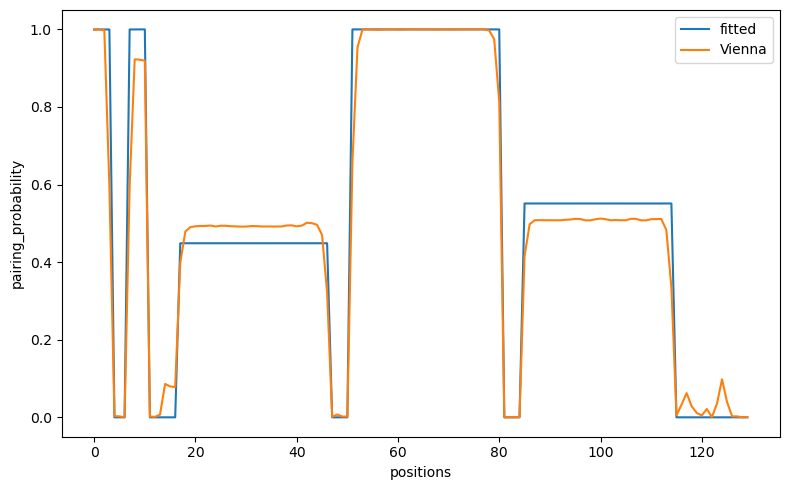

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
DO_RANDOM = False
# delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
delta_kcalpermol = 8
#coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
#id_str = f"r{REP_NUMBER}_true"
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
obj = lambda x: forward_model(N_reads, x, logweights, logM)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T-free_en) @ (logweights_fitted - free_en - logweights)

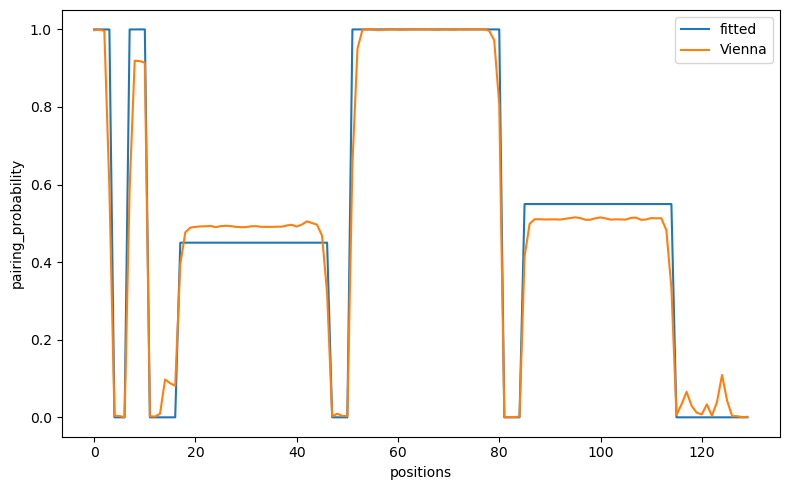

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
# id_str = "single_struct"
id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
#id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
obj = lambda x: forward_model(N_reads, x, logweights, logM)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T-free_en) @ (logweights_fitted - free_en - logweights)

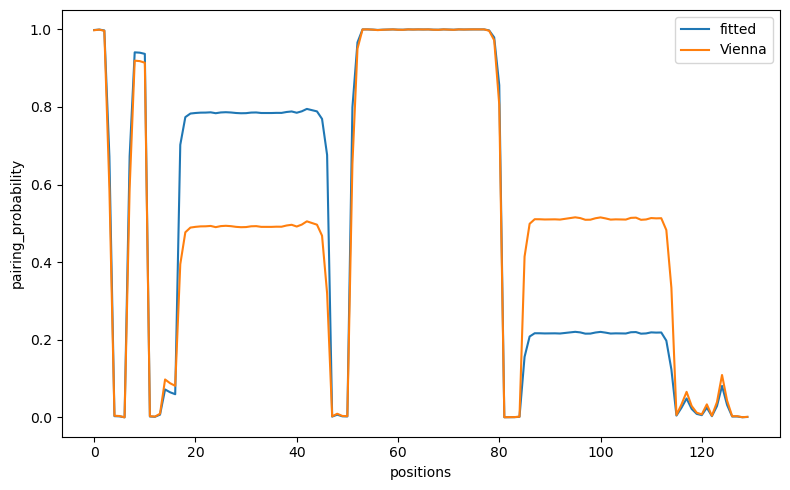

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
import os
import pathlib
import sys
import json
import time
import pickle
import argparse
import multiprocessing
from concurrent.futures import ProcessPoolExecutor, as_completed

_repo_root = pathlib.Path(__file__).resolve().parents[2]
os.environ.setdefault('RNA_STRUCT_HOME', str(_repo_root))
sys.path.insert(0, os.environ['RNA_STRUCT_HOME'])
os.chdir(str(_repo_root))

import numpy as np
import pandas as pd
import ast
import matplotlib
import matplotlib.pyplot as plt

from merge_rna import Experiment, MultiSystemsFit

import RNA
import bussilab.rna2d as bussi
from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy.sparse import csr_matrix

In [ ]:
# =============================================================================
# Load a single NewseqWT experiment (by concentration + replicate)
# =============================================================================
CONC_MM = 80
REP_NUMBER = 1

_PHASE1_OUTPUT_DIR = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits', 'designed_sequence',
                                   'outputs', 'experimental_turner', 'phase1', 'newseqWT')
#phase1_params = os.path.join(_PHASE1_OUTPUT_DIR, 'params1D.txt')
phase1_params = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits_paper', 'designed_sequence',
                                   'experimental', 'strand_disp_turner.txt')
_eps_b_path = os.path.join(_PHASE1_OUTPUT_DIR, 'detailed', 'NewseqWT_eps_b.npy')
_manifest_path = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence',
                               'newseq_wt_experiments_manifest.csv')


def load_single_newseq_experiment(conc_mM, rep_number, manifest_path=_manifest_path):
    """Look up one NewseqWT experiment (by concentration + replicate) in the manifest and load it."""
    manifest = pd.read_csv(manifest_path)
    match = manifest[(manifest['conc_mM'] == conc_mM) & (manifest['rep_number'] == rep_number)]
    if len(match) != 1:
        raise ValueError(f"Expected exactly one manifest row for conc_mM={conc_mM}, "
                          f"rep_number={rep_number}, found {len(match)}")
    path_txt = os.path.expandvars(match.iloc[0]['path_txt'])
    return Experiment(path_txt)


exp = load_single_newseq_experiment(CONC_MM, REP_NUMBER)
print(f"Loaded {exp.system_name} @ {exp.conc_mM}mM, {exp.temp_C}°C, rep {exp.rep_number}")

seq = exp.seq

# Build a fit struct around this one experiment purely for calculations (never calls .fit()).
fit_struct = MultiSystemsFit([exp], validation_exps=None, infer_1D_sc=False, skip_output_setup=True)

# eps_b is a System-level quantity normally derived from 0mM controls; a single non-0mM
# experiment alone would default it to zeros, so load the one already fitted/saved
# from the full 12-experiment des_seq_fits.py run instead of recomputing it.
_eps_b = np.load(_eps_b_path)
fit_struct.systems[0].eps_b = _eps_b
fit_struct.systems[0].exp_fits_train[0].eps_b = _eps_b

Loaded NewseqWT @ 80mM, 37°C, rep 1


In [ ]:
# =============================================================================
# Compute mutation probability params
# =============================================================================

def compute_mutation_probabilities(fit_struct, phase1_params):
    """Compute mutation probabilities parameters needed in the form M_i = a_i + b_i*s_i."""

    params_1D_ref = np.loadtxt(phase1_params)[:8]
    params_dict_ref = fit_struct.pack_params(params_1D_ref, fit_struct.systems[0])

    mu_r, p_b, m0, m1 = (params_dict_ref['mu_r'], params_dict_ref['p_b'],
                            params_dict_ref['m0'], params_dict_ref['m1'])

    p_bind_dict = params_dict_ref['p_bind']

    exp_fit = fit_struct.systems[0].exp_fits_train[0]

    mu_j = mu_r + exp_fit.kBT * np.log((exp_fit.conc_mM + .1) / 1000) if exp_fit.conc_mM is not None else mu_r
    penalty = exp_fit.compute_penalty_m(mu_j, p_b)

    # compute mu dependent quantities (and p(c_b|s_b,n_b))
    _, _, p_cb_given_sb_nb = exp_fit.compute_mu_dependent_quantities(mu_j, p_b, p_bind_dict) # should work with the p_bind dict that should have the same form of pack_params
    p_reaction_given_unpaired_nb = np.zeros(exp_fit.N_seq)
    p_reaction_given_paired_nb = np.zeros(exp_fit.N_seq)
    for i,nb in enumerate(exp_fit.seq):    # weighted sum over s_b=0,1
        p_reaction_given_unpaired_nb[i] = p_cb_given_sb_nb[(0, nb)] # must be multiplied by *(1-pairing_probs[i])
        p_reaction_given_paired_nb[i] = p_cb_given_sb_nb[(1, nb)] # must be multiplied by *pairing_probs[i] 

    p_cb_unpaired = exp_fit.compute_p_cb(mu_j, p_b, p_bind_dict, np.zeros(exp_fit.N_seq))
    p_cb_paired = exp_fit.compute_p_cb(mu_j, p_b, p_bind_dict, np.ones(exp_fit.N_seq))
    a_i = exp_fit.compute_mutation_profile(m0, m1, exp_fit.eps_b, p_cb_unpaired)
    b_i = exp_fit.compute_mutation_profile(m0, m1, exp_fit.eps_b, p_cb_paired) - a_i

    return p_reaction_given_unpaired_nb, p_reaction_given_paired_nb, a_i, b_i, penalty

p_reaction_given_unpaired_nb, p_reaction_given_paired_nb, a_i, b_i, penalty = compute_mutation_probabilities(fit_struct, phase1_params)

In [ ]:
def structures_sampling(seq, penalty, delta, lambda_sc=None, temperature_C=37):
    """Compute the forward model for the mutation probabilities."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    coverage_of_part_func = mol.suboptimal_coverage(delta)
    structures = mol.suboptimal_structures(delta)

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.suboptimal_to_numpy(suboptimal = structures, temperature=temperature_C+273.15) 
    return coverage_of_part_func, states, logweights

def structures_sampling_random(seq, penalty, number_samples, lambda_sc=None, temperature_C=37):
    """Compute the forward model for the mutation probabilities."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    structures = mol.sample(number_samples)
    energies = np.array([mol.evaluate(struct) for struct in structures])
    log_coverage = logsumexp(-(energies-mol.total_free_energy())*(1/(bussi._KB*(temperature_C+273.15))))

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.sample_to_numpy(samples = structures, temperature=temperature_C+273.15) 
    return np.exp(log_coverage), states, logweights

def forward_model_fixed_params(states, a_i, b_i, mask = None):
    """Compute the matrix that needs to be used for all logweights and reads,
    this stores the information about the sampled structures once.
    Returns a matrix of shape (N_samples, N_seq) with the mutation probabilities for each sampled structure and each sequence position.
    """
    if mask is None:
        mask = np.ones(len(a_i), bool)

    # unpaired (-1) -> a_i, paired -> a_i + b_i; masked columns set to 0
    mutation_probs = np.where(states == -1, a_i, a_i + b_i) * mask
    return mutation_probs

def precompute_read_factors(reads, mutation_probs, mask = None):
    """Weight-independent factors such that logM[r,s] = log P(read r | structure s) = (X @ D.T + base)[r,s].
    Masked positions (mask False) are unobserved: they contribute a factor 1 to every read
    (mutations falling on masked sites are ignored).
    Returns X (sparse, N_reads x N_observed), D (N_samples x N_observed), base (N_samples,)."""
    if mask is None:
        mask = np.ones(mutation_probs.shape[1], bool)
    observed = np.where(mask)[0]
    col_of_site = -np.ones(len(mask), int)
    col_of_site[observed] = np.arange(len(observed))

    # sparse binary matrix of mutated observed sites, shape (N_reads, N_observed)
    rows, cols = [], []
    for r, read in enumerate(reads):
        for site in read:
            if mask[site]:
                rows.append(r)
                cols.append(col_of_site[site])
    X = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(reads), len(observed)))

    # log M = sum_mut log p + sum_unmut log(1-p) = X @ (log p - log(1-p)) + sum_all log(1-p)
    P = mutation_probs[:, observed]
    log1mP = np.log1p(-P)
    D = np.log(P) - log1mP
    return X, D, log1mP.sum(axis=1)

def precompute_log_read_likelihood(reads, mutation_probs, mask = None):
    """Compute logM[r,s] = log P(read r | structure s), which does not depend on the weights.
    Returns a matrix of shape (N_reads, N_samples): memory N_reads*N_samples*8 bytes,
    use forward_model_chunked when this is too large."""
    X, D, base = precompute_read_factors(reads, mutation_probs, mask)
    return np.asarray(X @ D.T) + base[None, :]

def _loss_and_ratio_sum(N_reads, log_p, logM):
    """For a block of reads: loss = -sum_r N_r log L_r and ratio_sum_j = sum_r N_r M_rj / L_r,
    with L_r = sum_s p_s M_rs and log_p the normalized log probabilities of the structures."""
    # log read likelihoods log L_r = log sum_s P(s) M_rs
    log_L = logsumexp(logM + log_p[None, :], axis=1)
    return -np.dot(N_reads, log_L), N_reads @ np.exp(logM - log_L[:, None])

def forward_model(N_reads, logweights, logweights_0, logM, with_dkl = True, alpha = 0.1):
    """Compute loss and derivatives approximately using ensemble of suboptimal structures.
    P(s) = P0(s) W(s) / Z with logweights = log(W); the gradient is taken w.r.t. W.
    logM comes from precompute_log_read_likelihood."""
    log_Z = logsumexp(logweights + logweights_0)

    # i'm considering a negative log likelihood
    likelihood, ratio_sum = _loss_and_ratio_sum(N_reads, logweights + logweights_0 - log_Z, logM)
    kl = (np.exp((logweights + logweights_0 - log_Z)) @ logweights) - log_Z
    loss = likelihood + alpha*kl

    # dlogL_r/dW_j = (P0_j/Z) (M_rj/L_r - 1)
    # (multiply by W = exp(logweights - logweights_0) to get the gradient w.r.t. log W)
    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))
    grad += alpha*(2*(np.exp(logweights + logweights_0 - log_Z))-np.exp(logweights_0 - log_Z)*(1+kl+log_Z))

    return loss, grad

def forward_model_chunked(N_reads, logweights, logweights_0, X, D, base, chunk_size = 256):
    """Same as forward_model, for a number of structures too large to store logM:
    logM is rebuilt for chunk_size reads at a time, so memory is O(chunk_size*N_samples).
    X, D, base come from precompute_read_factors."""
    log_Z = logsumexp(logweights)
    log_p = logweights - log_Z

    loss = 0.
    ratio_sum = np.zeros(len(logweights), float)
    for start in range(0, X.shape[0], chunk_size):
        stop = min(start + chunk_size, X.shape[0])
        logM_chunk = np.asarray(X[start:stop] @ D.T) + base[None, :]
        chunk_loss, chunk_ratio_sum = _loss_and_ratio_sum(N_reads[start:stop], log_p, logM_chunk)
        loss += chunk_loss
        ratio_sum += chunk_ratio_sum

    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))

    return loss, grad

In [ ]:
mol_test = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)))
_,min_free_en = mol_test.mfe()
tot_free_en = mol_test.total_free_energy()

print(f"The minimum free energy is {min_free_en} and the total one {tot_free_en} in kcal/mol")

The minimum free energy is -55.652029822375894 and the total one -56.94195556640625 in kcal/mol


In [ ]:
DO_RANDOM = False
# delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
delta_kcalpermol = 8
#coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
#id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
obj = lambda x: forward_model(N_reads, x, logweights, logM)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

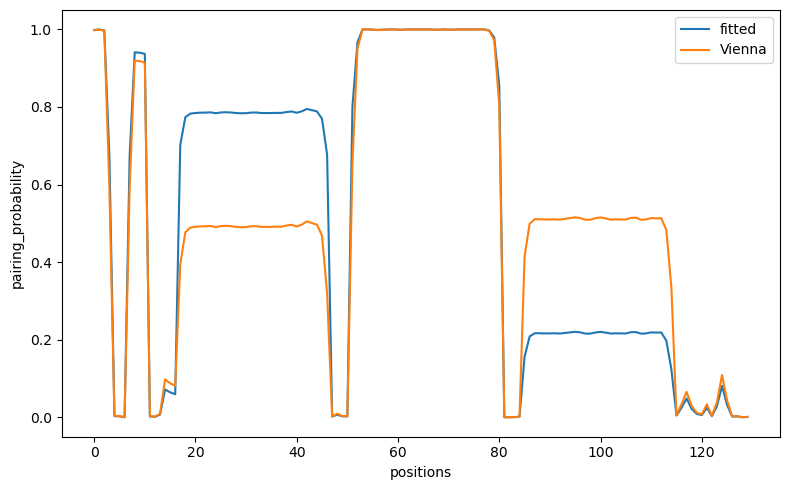

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
obj = lambda x: forward_model(N_reads, x, logweights, logM)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

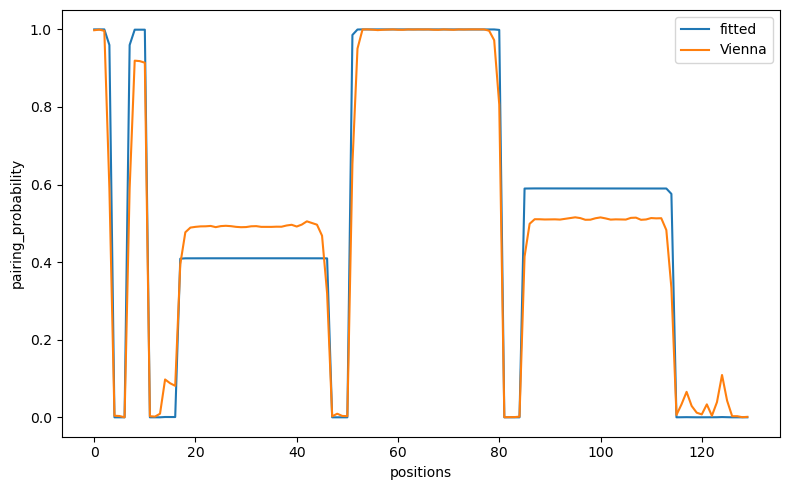

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
#####
# test with the true structures used for the sinthetic experiment
#####

bias = [[0,0],[0,-4]]
mol_0 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)), state_positions=[[80,86],[46,52]],state_biases=[bias,bias])

np.random.seed(42)
bussi.set_random_seed(42)

delta_good = 8
good_states_raw = mol_0.suboptimal_structures(delta_good)
good_states,_ = bussi.suboptimal_to_numpy(good_states_raw, temperature=37+273.15)

mol_00 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)))
vienna_logweights_of_good = mol_00.evaluate(good_states_raw) # could have also passed good_states

mutation_matrix_good = forward_model_fixed_params(good_states, a_i, b_i, mask=position_mask)

logM_good = precompute_log_read_likelihood(reads_int_list, mutation_matrix_good, mask=position_mask)
obj = lambda x: forward_model(N_reads, x, vienna_logweights_of_good, logM_good)

res=minimize(obj,np.zeros(len(vienna_logweights_of_good)),jac=True,method="L-BFGS-B")

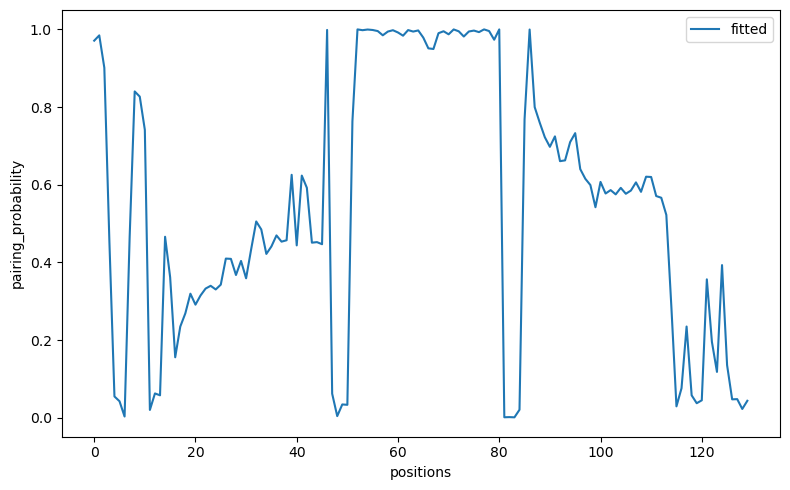

In [ ]:
logweights_fitted_good = res.x + vienna_logweights_of_good
pairing_states_good = np.where(good_states == -1, 0, 1)

free_en_good = logsumexp(logweights_fitted_good)
pairing_probs_good = np.exp(logweights_fitted_good.T-free_en_good) @ pairing_states_good

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs_good, label="fitted")

ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
good_states.shape

(67828, 130)

In [ ]:
#####
# test with the true structures used for the sinthetic experiment
#####

bias = [[0,0],[0,-4]]
mol_0 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)), state_positions=[[80,86],[46,52]],state_biases=[bias,bias])

np.random.seed(42)
bussi.set_random_seed(42)

delta_good = 4
good_states_raw = mol_0.suboptimal_structures(delta_good)
good_states,_ = bussi.suboptimal_to_numpy(good_states_raw, temperature=37+273.15)

mol_00 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)))
vienna_logweights_of_good = mol_00.evaluate(good_states_raw) # could have also passed good_states

In [ ]:
good_states.shape

(769, 130)

In [ ]:
#####
# test with the true structures used for the sinthetic experiment
#####

bias = [[0,0],[0,-4]]
mol_0 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)), state_positions=[[80,86],[46,52]],state_biases=[bias,bias])

np.random.seed(42)
bussi.set_random_seed(42)

delta_good = 8
good_states_raw = mol_0.suboptimal_structures(delta_good)
good_states,_ = bussi.suboptimal_to_numpy(good_states_raw, temperature=37+273.15)

mol_00 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)))
vienna_logweights_of_good = mol_00.evaluate(good_states_raw) # could have also passed good_states

In [ ]:
mol_0.suboptimal_coverage(delta_good)

0.9889455930957217

In [ ]:
#####
# test with the true structures used for the sinthetic experiment
#####

bias = [[0,0],[0,-4]]
mol_0 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)), state_positions=[[80,86],[46,52]],state_biases=[bias,bias])

np.random.seed(42)
bussi.set_random_seed(42)

delta_good = 5
good_states_raw = mol_0.suboptimal_structures(delta_good)
good_states,_ = bussi.suboptimal_to_numpy(good_states_raw, temperature=37+273.15)

mol_00 = bussi.Molecule(seq, lambdas1d=penalty*np.ones(len(seq)))
vienna_logweights_of_good = mol_00.evaluate(good_states_raw) # could have also passed good_states

In [ ]:
good_states.shape

(2619, 130)

In [ ]:
mol_0.suboptimal_coverage(delta_good)

0.9178547761334332

In [ ]:
mutation_matrix_good = forward_model_fixed_params(good_states, a_i, b_i, mask=position_mask)
logM_good = precompute_log_read_likelihood(reads_int_list, mutation_matrix_good, mask=position_mask)

obj = lambda x: forward_model(N_reads, x, vienna_logweights_of_good, logM_good)
res=minimize(obj,np.zeros(len(vienna_logweights_of_good)),jac=True,method="L-BFGS-B")

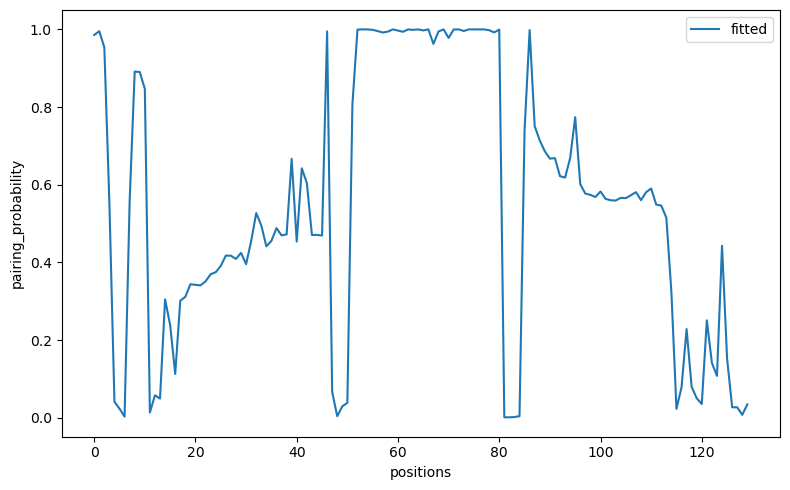

In [ ]:
logweights_fitted_good = res.x + vienna_logweights_of_good
pairing_states_good = np.where(good_states == -1, 0, 1)

free_en_good = logsumexp(logweights_fitted_good)
pairing_probs_good = np.exp(logweights_fitted_good.T-free_en_good) @ pairing_states_good

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs_good, label="fitted")

ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

###
# function for doing the optimization(ensemble for fit, experimental data)
# 
###

In [ ]:
DO_RANDOM = False
# delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
delta_kcalpermol = 10
#coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
test_loss, test_grad = forward_model_chunked(N_reads, test_logweights, logweights, X, D, base)

In [ ]:
test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
test_loss, test_grad = forward_model_chunked(N_reads, test_logweights, logweights, X, D, base)

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

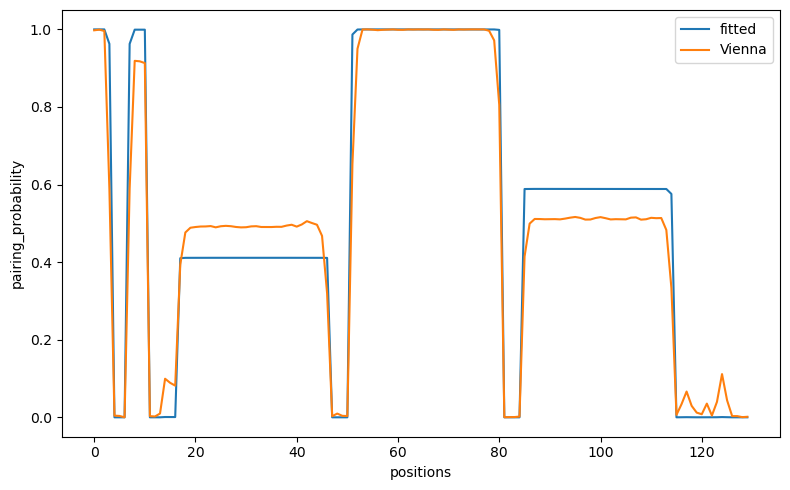

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
DO_RANDOM = True

if DO_RANDOM:
    number_of_structures = 10000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

TypeError: sample_to_numpy() got an unexpected keyword argument 'temperature'

In [ ]:
def structures_sampling(seq, penalty, delta, lambda_sc=None, temperature_C=37):
    """Enumerate the structures that will be reweighted, starting from the mfe up to delta_E."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    coverage_of_part_func = mol.suboptimal_coverage(delta)
    structures = mol.suboptimal_structures(delta)

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.suboptimal_to_numpy(suboptimal = structures, temperature=temperature_C+273.15) 
    return coverage_of_part_func, states, logweights

def structures_sampling_random(seq, penalty, number_samples, lambda_sc=None, temperature_C=37):
    """Sample randomly the structures that will be reweighted."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    structures = mol.sample(number_samples)
    energies = np.array([mol.evaluate(struct) for struct in structures])
    log_coverage = logsumexp(-(energies-mol.total_free_energy())*(1/(bussi._KB*(temperature_C+273.15))))

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.sample_to_numpy(samples = structures, deduplicate= True) 
    return np.exp(log_coverage), states, logweights

def forward_model_fixed_params(states, a_i, b_i, mask = None):
    """Compute the matrix that needs to be used for all logweights and reads,
    this stores the information about the sampled structures once.
    Returns a matrix of shape (N_samples, N_seq) with the mutation probabilities for each sampled structure and each sequence position.
    """
    if mask is None:
        mask = np.ones(len(a_i), bool)

    # unpaired (-1) -> a_i, paired -> a_i + b_i; masked columns set to 0
    mutation_probs = np.where(states == -1, a_i, a_i + b_i) * mask
    return mutation_probs

def precompute_read_factors(reads, mutation_probs, mask = None):
    """Weight-independent factors such that logM[r,s] = log P(read r | structure s) = (X @ D.T + base)[r,s].
    Masked positions (mask False) are unobserved: they contribute a factor 1 to every read
    (mutations falling on masked sites are ignored).
    Returns X (sparse, N_reads x N_observed), D (N_samples x N_observed), base (N_samples,)."""
    if mask is None:
        mask = np.ones(mutation_probs.shape[1], bool)
    observed = np.where(mask)[0]
    col_of_site = -np.ones(len(mask), int)
    col_of_site[observed] = np.arange(len(observed))

    # sparse binary matrix of mutated observed sites, shape (N_reads, N_observed)
    rows, cols = [], []
    for r, read in enumerate(reads):
        for site in read:
            if mask[site]:
                rows.append(r)
                cols.append(col_of_site[site])
    X = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(reads), len(observed)))

    # log M = sum_mut log p + sum_unmut log(1-p) = X @ (log p - log(1-p)) + sum_all log(1-p)
    P = mutation_probs[:, observed]
    log1mP = np.log1p(-P)
    D = np.log(P) - log1mP
    return X, D, log1mP.sum(axis=1)

def precompute_log_read_likelihood(reads, mutation_probs, mask = None):
    """Compute logM[r,s] = log P(read r | structure s), which does not depend on the weights.
    Returns a matrix of shape (N_reads, N_samples): memory N_reads*N_samples*8 bytes,
    use forward_model_chunked when this is too large."""
    X, D, base = precompute_read_factors(reads, mutation_probs, mask)
    return np.asarray(X @ D.T) + base[None, :]

def _loss_and_ratio_sum(N_reads, log_p, logM):
    """For a block of reads: loss = -sum_r N_r log L_r and ratio_sum_j = sum_r N_r M_rj / L_r,
    with L_r = sum_s p_s M_rs and log_p the normalized log probabilities of the structures."""
    # log read likelihoods log L_r = log sum_s P(s) M_rs
    log_L = logsumexp(logM + log_p[None, :], axis=1)
    return -np.dot(N_reads, log_L), N_reads @ np.exp(logM - log_L[:, None])

def forward_model(N_reads, logweights, logweights_0, logM, with_dkl = True, alpha = 0.1):
    """Compute loss and derivatives approximately using ensemble of suboptimal structures.
    P(s) = P0(s) W(s) / Z with logweights = log(W); the gradient is taken w.r.t. W.
    logM comes from precompute_log_read_likelihood."""
    log_Z = logsumexp(logweights + logweights_0)

    # i'm considering a negative log likelihood
    likelihood, ratio_sum = _loss_and_ratio_sum(N_reads, logweights + logweights_0 - log_Z, logM)
    kl = (np.exp((logweights + logweights_0 - log_Z)) @ logweights) - log_Z
    loss = likelihood + alpha*kl

    # dlogL_r/dW_j = (P0_j/Z) (M_rj/L_r - 1)
    # (multiply by W = exp(logweights - logweights_0) to get the gradient w.r.t. log W)
    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))
    grad += alpha*(2*(np.exp(logweights + logweights_0 - log_Z))-np.exp(logweights_0 - log_Z)*(1+kl+log_Z))

    return loss, grad

def forward_model_chunked(N_reads, logweights, logweights_0, X, D, base, alpha=0.1, chunk_size = 256):
    """Same as forward_model, for a number of structures too large to store logM:
    logM is rebuilt for chunk_size reads at a time, so memory is O(chunk_size*N_samples).
    X, D, base come from precompute_read_factors."""
    log_Z = logsumexp(logweights)
    log_p = logweights - log_Z

    likelihood = 0.
    ratio_sum = np.zeros(len(logweights), float)
    for start in range(0, X.shape[0], chunk_size):
        stop = min(start + chunk_size, X.shape[0])
        logM_chunk = np.asarray(X[start:stop] @ D.T) + base[None, :]
        chunk_likelihood, chunk_ratio_sum = _loss_and_ratio_sum(N_reads[start:stop], log_p, logM_chunk)
        likelihood += chunk_likelihood
        ratio_sum += chunk_ratio_sum

    if alpha > 0:
        kl = (np.exp((logweights + logweights_0 - log_Z)) @ logweights) - log_Z
        loss = likelihood + alpha*kl
    else:
        loss = likelihood 

    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))

    if alpha > 0:
        grad += alpha*(2*(np.exp(logweights + logweights_0 - log_Z))-np.exp(logweights_0 - log_Z)*(1+kl+log_Z))


    return loss, grad

In [ ]:
DO_RANDOM = True

if DO_RANDOM:
    number_of_structures = 10000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
coverage_of_structures

4.061511679795404e-33

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
test_loss, test_grad = forward_model_chunked(N_reads, test_logweights, logweights, X, D, base)

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

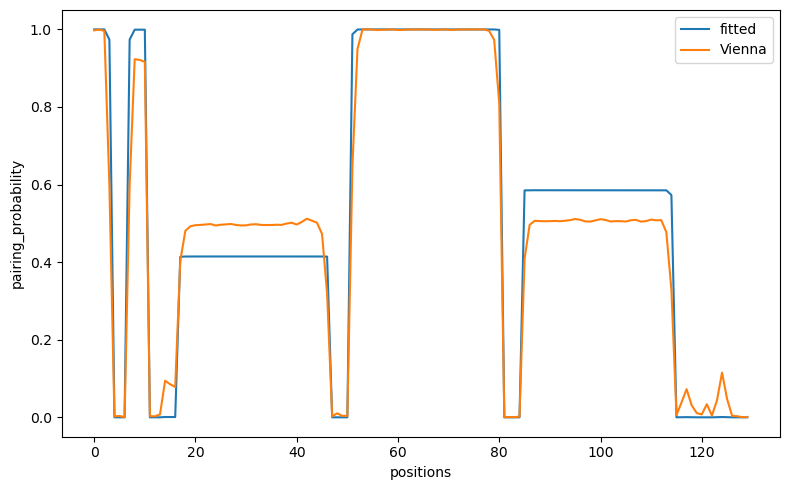

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
DO_RANDOM = True

if DO_RANDOM:
    number_of_structures = 100000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

ValueError: operands could not be broadcast together with shapes (4585,989) (1,4833) 

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

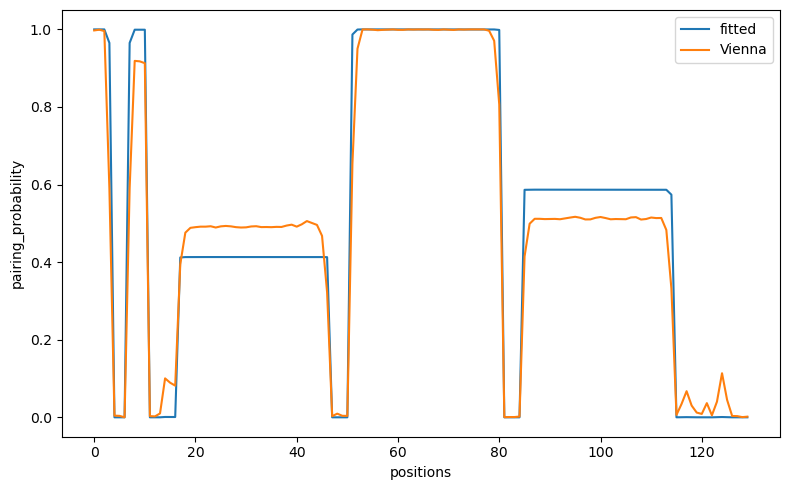

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
states.shape

(4833, 130)

In [ ]:
DO_RANDOM = True

if DO_RANDOM:
    number_of_structures = 500000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

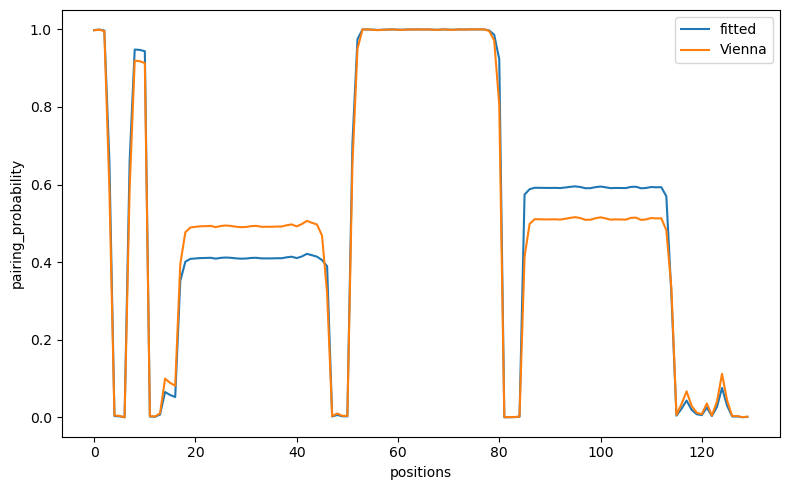

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
states.shape

(13092, 130)

In [ ]:
DO_RANDOM = True

if DO_RANDOM:
    number_of_structures = 1000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
test_loss, test_grad = forward_model_chunked(N_reads, test_logweights, logweights, X, D, base)

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

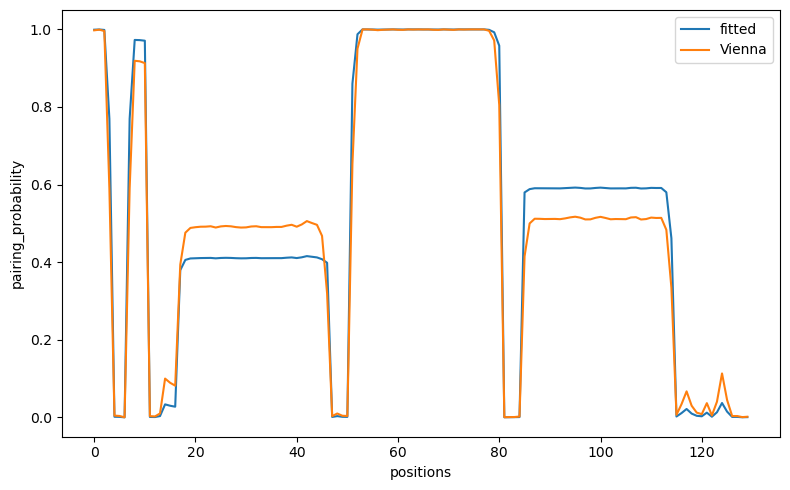

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
states.shape

(20057, 130)

In [ ]:
DO_RANDOM = True

if DO_RANDOM:
    number_of_structures = 5000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
states.shape

(54121, 130)

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
test_loss, test_grad = forward_model(N_reads, test_logweights, logweights, logM)

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

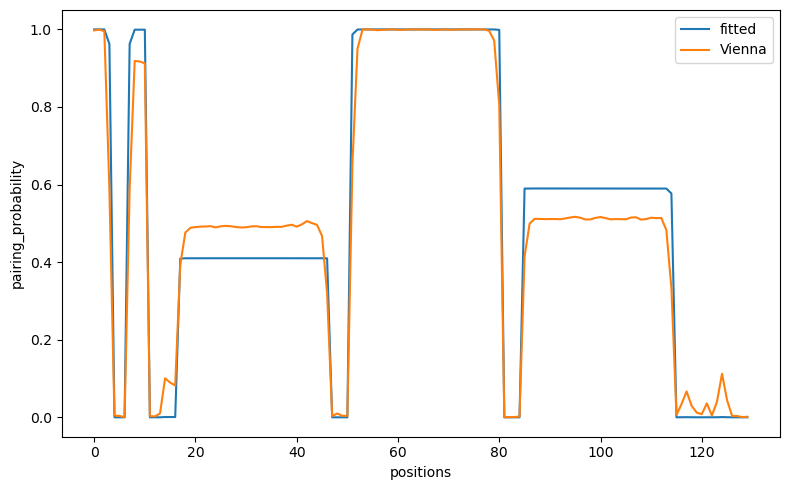

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
DO_RANDOM = False

if DO_RANDOM:
    number_of_structures = 5000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 12

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
states.shape

(965288, 130)

In [ ]:
DO_RANDOM = False

if DO_RANDOM:
    number_of_structures = 5000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 10.5

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
states.shape

(238150, 130)

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
test_loss, test_grad = forward_model_chunked(N_reads, test_logweights, logweights, X, D, base)

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

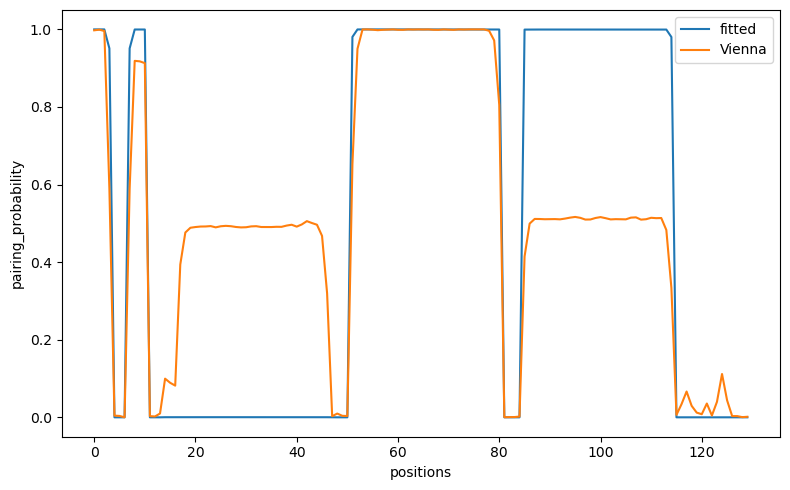

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
import os
import pathlib
import sys

_repo_root = pathlib.Path(__file__).resolve().parents[2]
os.environ.setdefault('RNA_STRUCT_HOME', str(_repo_root))
sys.path.insert(0, os.environ['RNA_STRUCT_HOME'])
os.chdir(str(_repo_root))

import numpy as np
import pandas as pd

import bussilab.rna2d as bussi

In [ ]:
# import the physical params and sc from Giuses fit
phase1_params = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits_paper', 'designed_sequence',
                                   'experimental', 'strand_disp_turner.txt')

_designed_seq_dir = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence')
newseq_wt_fasta_path = os.path.join(_designed_seq_dir, 'Newseq_WT.fasta')

with open(newseq_wt_fasta_path, "r") as file:
    line2 = file[1]
    print(line2)

TypeError: '_io.TextIOWrapper' object is not subscriptable

In [ ]:
# import the physical params and sc from Giuses fit
phase1_params = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits_paper', 'designed_sequence',
                                   'experimental', 'strand_disp_turner.txt')

_designed_seq_dir = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence')
newseq_wt_fasta_path = os.path.join(_designed_seq_dir, 'Newseq_WT.fasta')

with open(newseq_wt_fasta_path, "r") as file:
    line = file.readline()
    while line:
        print(line.strip())
        line = file.readline()

>Newseq_WT
GGCAUUAUGCCACAGCCAAUCCCCACUUCAACUCACAACUAUUCCAAAAAAUUGGAAUAGUUGUGAGUUGAAGUGGGGAUUAAAAAAUCCCCACUUCAACUCACAACUAUUCCAACCUCCAGCAGACCAU


In [ ]:
# import the physical params and sc from Giuses fit
phase1_params = os.path.join(os.environ['RNA_STRUCT_HOME'], 'fits_paper', 'designed_sequence',
                                   'experimental', 'strand_disp_turner.txt')

_designed_seq_dir = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence')
newseq_wt_fasta_path = os.path.join(_designed_seq_dir, 'Newseq_WT.fasta')

with open(newseq_wt_fasta_path, "r") as file:
    for i, line in enumerate(file):
        if i == 1:
            seq = line.strip()

In [ ]:
seq

'GGCAUUAUGCCACAGCCAAUCCCCACUUCAACUCACAACUAUUCCAAAAAAUUGGAAUAGUUGUGAGUUGAAGUGGGGAUUAAAAAAUCCCCACUUCAACUCACAACUAUUCCAACCUCCAGCAGACCAU'

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
def structures_sampling(seq, penalty, delta, lambda_sc=None, temperature_C=37):
    """Enumerate the structures that will be reweighted, starting from the mfe up to delta_E."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    # coverage_of_part_func = mol.suboptimal_coverage(delta)
    coverage_of_part_func = None
    structures = mol.suboptimal_structures(delta)

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.suboptimal_to_numpy(suboptimal = structures, temperature=temperature_C+273.15) 
    return coverage_of_part_func, states, logweights

def structures_sampling_random(seq, penalty, number_samples, lambda_sc=None, temperature_C=37):
    """Sample randomly the structures that will be reweighted."""
    # the starting penalty for paired sites, from DMS presence and lambda_sc if available
    if lambda_sc is not None:
        lambdas1d = penalty * np.ones(len(seq)) + lambda_sc
    else:
        lambdas1d = penalty * np.ones(len(seq))

    # define molecule used for sub_optimal structure sampling
    # default parameters should be turner 2004
    mol = bussi.Molecule(seq, lambdas1d=lambdas1d, temperature=temperature_C+273.15) 

    structures = mol.sample(number_samples)
    energies = np.array([mol.evaluate(struct) for struct in structures])
    log_coverage = logsumexp(-(energies-mol.total_free_energy())*(1/(bussi._KB*(temperature_C+273.15))))

    # in principle one can sample at a diff temp then the one used for weights
    states, logweights = bussi.sample_to_numpy(samples = structures, deduplicate= True) 
    return np.exp(log_coverage), states, logweights

def forward_model_fixed_params(states, a_i, b_i, mask = None):
    """Compute the matrix that needs to be used for all logweights and reads,
    this stores the information about the sampled structures once.
    Returns a matrix of shape (N_samples, N_seq) with the mutation probabilities for each sampled structure and each sequence position.
    """
    if mask is None:
        mask = np.ones(len(a_i), bool)

    # unpaired (-1) -> a_i, paired -> a_i + b_i; masked columns set to 0
    mutation_probs = np.where(states == -1, a_i, a_i + b_i) * mask
    return mutation_probs

def precompute_read_factors(reads, mutation_probs, mask = None):
    """Weight-independent factors such that logM[r,s] = log P(read r | structure s) = (X @ D.T + base)[r,s].
    Masked positions (mask False) are unobserved: they contribute a factor 1 to every read
    (mutations falling on masked sites are ignored).
    Returns X (sparse, N_reads x N_observed), D (N_samples x N_observed), base (N_samples,)."""
    if mask is None:
        mask = np.ones(mutation_probs.shape[1], bool)
    observed = np.where(mask)[0]
    col_of_site = -np.ones(len(mask), int)
    col_of_site[observed] = np.arange(len(observed))

    # sparse binary matrix of mutated observed sites, shape (N_reads, N_observed)
    rows, cols = [], []
    for r, read in enumerate(reads):
        for site in read:
            if mask[site]:
                rows.append(r)
                cols.append(col_of_site[site])
    X = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(reads), len(observed)))

    # log M = sum_mut log p + sum_unmut log(1-p) = X @ (log p - log(1-p)) + sum_all log(1-p)
    P = mutation_probs[:, observed]
    log1mP = np.log1p(-P)
    D = np.log(P) - log1mP
    return X, D, log1mP.sum(axis=1)

def precompute_log_read_likelihood(reads, mutation_probs, mask = None):
    """Compute logM[r,s] = log P(read r | structure s), which does not depend on the weights.
    Returns a matrix of shape (N_reads, N_samples): memory N_reads*N_samples*8 bytes,
    use forward_model_chunked when this is too large."""
    X, D, base = precompute_read_factors(reads, mutation_probs, mask)
    return np.asarray(X @ D.T) + base[None, :]

def _loss_and_ratio_sum(N_reads, log_p, logM):
    """For a block of reads: loss = -sum_r N_r log L_r and ratio_sum_j = sum_r N_r M_rj / L_r,
    with L_r = sum_s p_s M_rs and log_p the normalized log probabilities of the structures."""
    # log read likelihoods log L_r = log sum_s P(s) M_rs
    log_L = logsumexp(logM + log_p[None, :], axis=1)
    return -np.dot(N_reads, log_L), N_reads @ np.exp(logM - log_L[:, None])

def forward_model(N_reads, logweights, logweights_0, logM, with_dkl = True, alpha = 0.1):
    """Compute loss and derivatives approximately using ensemble of suboptimal structures.
    P(s) = P0(s) W(s) / Z with logweights = log(W); the gradient is taken w.r.t. W.
    logM comes from precompute_log_read_likelihood."""
    log_Z = logsumexp(logweights + logweights_0)

    # i'm considering a negative log likelihood
    likelihood, ratio_sum = _loss_and_ratio_sum(N_reads, logweights + logweights_0 - log_Z, logM)
    kl = (np.exp((logweights + logweights_0 - log_Z)) @ logweights) - log_Z
    loss = likelihood + alpha*kl

    # dlogL_r/dW_j = (P0_j/Z) (M_rj/L_r - 1)
    # (multiply by W = exp(logweights - logweights_0) to get the gradient w.r.t. log W)
    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))
    grad += alpha*(2*(np.exp(logweights + logweights_0 - log_Z))-np.exp(logweights_0 - log_Z)*(1+kl+log_Z))

    return loss, grad

def forward_model_chunked(N_reads, logweights, logweights_0, X, D, base, alpha=0.1, chunk_size = 256):
    """Same as forward_model, for a number of structures too large to store logM:
    logM is rebuilt for chunk_size reads at a time, so memory is O(chunk_size*N_samples).
    X, D, base come from precompute_read_factors."""
    log_Z = logsumexp(logweights)
    log_p = logweights - log_Z

    likelihood = 0.
    ratio_sum = np.zeros(len(logweights), float)
    for start in range(0, X.shape[0], chunk_size):
        stop = min(start + chunk_size, X.shape[0])
        logM_chunk = np.asarray(X[start:stop] @ D.T) + base[None, :]
        chunk_likelihood, chunk_ratio_sum = _loss_and_ratio_sum(N_reads[start:stop], log_p, logM_chunk)
        likelihood += chunk_likelihood
        ratio_sum += chunk_ratio_sum

    if alpha > 0:
        kl = (np.exp((logweights + logweights_0 - log_Z)) @ logweights) - log_Z
        loss = likelihood + alpha*kl
    else:
        loss = likelihood 

    grad = -np.exp(logweights_0 - log_Z) * (ratio_sum - np.sum(N_reads))

    if alpha > 0:
        grad += alpha*(2*(np.exp(logweights + logweights_0 - log_Z))-np.exp(logweights_0 - log_Z)*(1+kl+log_Z))


    return loss, grad

In [ ]:
DO_RANDOM = False

if DO_RANDOM:
    number_of_structures = 5000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 5

    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

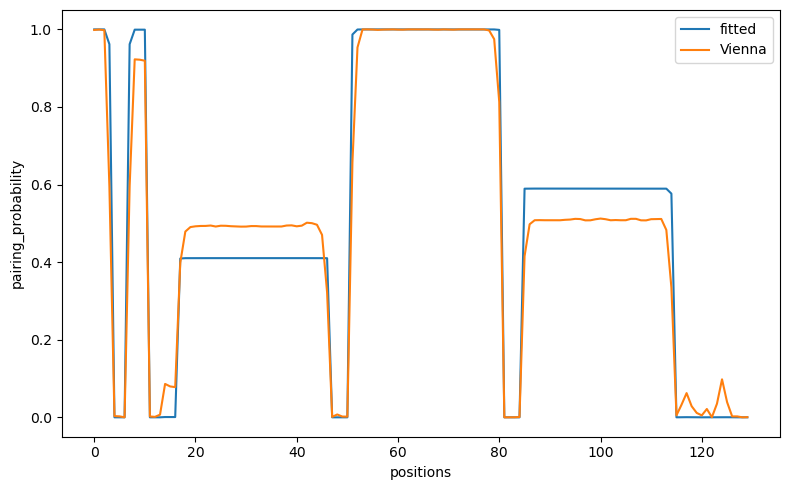

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
DO_RANDOM = False

if DO_RANDOM:
    number_of_structures = 5000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 5

    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

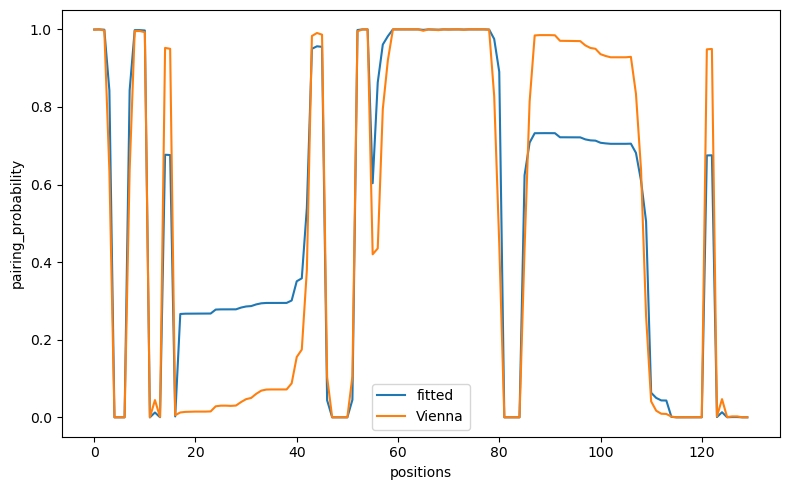

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
DO_RANDOM = False

if DO_RANDOM:
    number_of_structures = 5000000

    coverage_of_part_func, states, logweights = structures_sampling_random(seq, penalty, number_of_structures)
else:
    # delta 10 -> 145625 struct, 0.998 coverage, delta 5 -> 815 struct, 0.944 coverage
    delta_kcalpermol = 8

    coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol, lambda_sc= np.loadtxt(phase1_params)[8:])
    #coverage_of_part_func, states, logweights = structures_sampling(seq, penalty, delta_kcalpermol)

possible_structures_number = 2.1614 * len(seq)**(-3/2)* 1.96798**len(seq) # asymptotic formula
coverage_of_structures = states.shape[0]/possible_structures_number

In [ ]:
# id_str = "single_struct"
# id_str = f"r{REP_NUMBER}_true" # this is the forceded population of 80%
id_str = f"r{REP_NUMBER}" # this is the forceded strand_displacement

path_synthetic_data = os.path.join(os.environ['RNA_STRUCT_HOME'], 'data', 'designed_sequence', 'synthetic_mutation_experiments')
df = pd.read_csv(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+".csv"))
# mask saved by generate_synth_mut_experiment.py (True = observed/fitted position, kept indexing of exp.seq)
position_mask = np.load(os.path.join(path_synthetic_data, f"synthetic_{CONC_MM}mM_"+id_str+"_mask.npy"))
assert len(position_mask) == len(seq), f"mask length {len(position_mask)} != sequence length {len(seq)}"

mutation_matrix = forward_model_fixed_params(states, a_i, b_i, mask=position_mask)

reads_str = df['mut_positions'].values
reads_int_list = [ast.literal_eval(read) for read in reads_str]
N_reads = df['occurrences'].values

# weight-independent, compute once
logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)

test_logcorrections = 1. * np.random.randn(len(logweights))
test_logweights = test_logcorrections+logweights
test_logweights = test_logweights-np.log(np.sum(np.exp(test_logweights)))

In [ ]:
states.shape

(39606, 130)

In [ ]:
if len(logweights)<200000:
    logM = precompute_log_read_likelihood(reads_int_list, mutation_matrix, mask=position_mask)
    obj = lambda x: forward_model(N_reads, x, logweights, logM)
else:
    X, D, base = precompute_read_factors(reads_int_list, mutation_matrix, position_mask)
    obj = lambda x: forward_model_chunked(N_reads, x, logweights, X, D, base)

res=minimize(obj,np.zeros(len(logweights)),jac=True,method="L-BFGS-B")

In [ ]:
# calculate and plot the pairing probabilities
logweights_fitted = res.x + logweights
pairing_states = np.where(states == -1, 0, 1)

free_en = logsumexp(logweights_fitted)
pairing_probs = np.exp(logweights_fitted.T-free_en) @ pairing_states
pairing_probs_0 = np.exp(logweights.T) @ pairing_states

correlation_matrix = np.zeros([states.shape[1],states.shape[1]])

for struct_ind in np.arange(states.shape[0]):
    state = pairing_states[struct_ind,:][np.newaxis]
    correlation_matrix += (state.T @ state)*np.exp(logweights_fitted[struct_ind]-free_en)

unconn_correl_matrix = correlation_matrix-np.matmul(np.atleast_2d(pairing_probs).T, np.atleast_2d(pairing_probs))

d_kl = np.exp(logweights_fitted.T+logweights.T-free_en) @ (logweights_fitted - free_en)

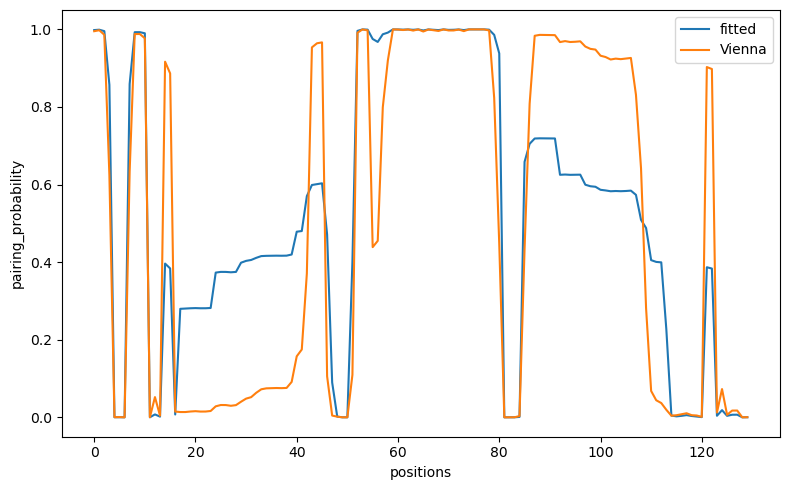

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pairing_probs, label="fitted")
ax.plot(pairing_probs_0, label="Vienna")
ax.set_xlabel('positions')
ax.set_ylabel('pairing_probability')
ax.legend()
fig.tight_layout()

In [ ]:
position_mask

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [ ]:
bussi._SUPPORTS_SUBOPT_SOFT_CONSTRAINTS

False

Connected to merge-rna-patched-2 (Python 3.12.9)